In [16]:
import json, math, random, shutil, sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from tqdm.auto import tqdm
import gc, hashlib, itertools, json, math, pickle, random, shutil, sys

sys.path.insert(0, "kev")
from models.kev_pointer import KevPointerModel
import seaborn as sns
import matplotlib.pyplot as plt
from cycler import cycler

LANCET_PALETTE = ["#1B365D", "#9E2A2B", "#2E8B78", "#D9822B", "#6F5091", "#4A6F8A"]
plt.rcParams["axes.prop_cycle"] = cycler(color=LANCET_PALETTE)

def make_one_hot(row):
    codes = row["option_codes"]
    if len(codes) != len(row["option_texts"]):
        raise ValueError(f"{row['qid']}: option_codes ({len(codes)}) != option_texts ({len(row['option_texts'])})")
    idx = codes.index(row["answer_code"])
    vec = np.zeros(len(codes), dtype=np.float64)
    vec[idx] = 1.0
    return vec

In [2]:
COUNTRY_NAMES = {"US": "United States"}
AGE_BINS = [17, 29, 49, 64, 120]
AGE_LABELS = ["18-29", "30-49", "50-64", "65+"]

PERSONA_NAMES = {
    "c_alphan": "Country",
    "SEX": "Sex",
    "AGE": "Age",
    "EDULEVEL": "Education",
    "RELIGGRP": "Religion",
    "ATTEND": "Attendance of religious services",
    "PARTY_LR": "Political ideology",
    "VOTE_LE": "Voted in the last general election",
    "URBRURAL": "Place of living",
    "MARITAL": "Marital status",
    "MAINSTAT": "Main activity",
    "UNION": "Trade union membership",
    "US_PRTY": "Political party",
    "US_INC": "Income",
    "US_REG": "Region",
    "US_ETHN1": "Ancestry",
}

splits_by_year = json.loads(Path("splits/split.json").read_text())
split_frames = {"train": [], "valid": [], "test": []}

for year, year_splits in splits_by_year.items():
    df = pd.read_parquet(f"data/issp{year}/issp{year}_US_long.parquet")
    persona_cols = list(df.columns[1:df.columns.get_loc("v")])
    if persona_cols != list(PERSONA_NAMES.keys()):
        raise ValueError(f"{year}: persona columns mismatch: {persona_cols} != {list(PERSONA_NAMES.keys())}")

    df["c_alphan"] = [COUNTRY_NAMES[c] for c in df["c_alphan"]]
    age_num = pd.to_numeric(df["AGE"], errors="raise")
    age_bucketed = pd.cut(age_num, bins=AGE_BINS, labels=AGE_LABELS).astype(object)
    if int(age_bucketed.isna().sum()) != int(df["AGE"].isna().sum()):
        raise ValueError(f"{year}: some non-missing AGE values fell outside AGE_BINS")
    df["AGE"] = age_bucketed

    for col in ("option_codes", "option_texts"):
        df[col] = df[col].map(list)
    df["year"] = year
    df["qid"] = year + ":" + df["v"]
    df["one_hot"] = [make_one_hot(row) for _, row in df.iterrows()]

    for split_name in ("train", "valid", "test"):
        sub = df[df["v"].isin(year_splits[split_name])].copy()
        split_frames[split_name].append(sub)

train_df = pd.concat(split_frames["train"], ignore_index=True)
valid_df = pd.concat(split_frames["valid"], ignore_index=True)
test_df = pd.concat(split_frames["test"], ignore_index=True)

for name, sdf in (("train", train_df), ("valid", valid_df), ("test", test_df)):
    print(f"{name:<5}: {len(sdf):>7,} answers across {sdf['qid'].nunique():>3} questions")

train: 610,291 answers across 494 questions
valid:  64,201 answers across  50 questions
test :  92,992 answers across  72 questions


In [23]:
def make_record(sub_df, cols):
    if isinstance(sub_df, dict):
        row = sub_df
        human_dist = row["one_hot"]
        n = 1
    else:
        for c in cols:
            if sub_df[c].nunique(dropna=False) != 1:
                raise ValueError(f"sub_df must have a single value for {c!r}, got {sub_df[c].unique().tolist()}")
        row = sub_df.iloc[0]
        human_dist = np.stack(sub_df["one_hot"].values).mean(axis=0)
        n = len(sub_df)

    personas = {c: row[c] for c in cols if c != "c_alphan"}
    return {
        "qid": row["qid"],
        "year": row["year"],
        "v": row["v"],
        "type": row["type"],
        "question": row["question"],
        "option_texts": row["option_texts"],
        "country": row["c_alphan"],
        "personas": personas,
        "attribute": "+".join(personas.keys()) if personas else "none",
        "persona": ", ".join(f"{PERSONA_NAMES[c]}={v}" for c, v in personas.items()) if personas else "All",
        "n": n,
        "human_dist": human_dist,
    }



def consensus(probs):
    num_options = len(probs)
    if num_options <= 1:
        raise ValueError(f"consensus requires at least 2 options, got {num_options}")
    scale_points = np.arange(1, num_options + 1, dtype=float)
    mean_score = float(np.dot(scale_points, probs))
    return float(
        1.0 + np.sum(probs * np.log2(1.0 - np.abs(scale_points - mean_score) / (num_options - 1) + 1e-12))
    )


def build_persona_dataset(df, attr_sets=None, min_n=None, desc="build_persona_dataset", cache_dir=".cache"):
    cache_file = None
    if cache_dir is not None:
        key = repr((len(df), df["qid"].iloc[0], df["qid"].iloc[-1], attr_sets, min_n))
        digest = hashlib.md5(key.encode()).hexdigest()[:8]
        cache_file = Path(cache_dir) / f"{desc}_min{min_n}_{digest}.pkl"
        if cache_file.exists():
            with cache_file.open("rb") as f:
                records = pickle.load(f)
            print(f"Loaded {len(records):,} records from {cache_file}")
            return records

    records = []
    q_groups = list(df.groupby("qid", sort=False))
    for _, q_df in tqdm(q_groups, desc=desc, unit="question"):
        if attr_sets is None:
            for row in q_df.to_dict("records"):
                cols = [c for c in PERSONA_NAMES if c != "c_alphan" and pd.notna(row[c])]
                records.append(make_record(row, cols))
            continue

        sets = [[attr_sets]] if isinstance(attr_sets, str) else attr_sets
        for cols in sets:
            cols = [cols] if isinstance(cols, str) else list(cols)
            if not cols:
                if min_n is None or len(q_df) >= min_n:
                    records.append(make_record(q_df, cols))
                continue
            for _, sub_df in q_df.groupby(cols, sort=False, observed=True):
                if min_n is None or len(sub_df) >= min_n:
                    records.append(make_record(sub_df, cols))

    if cache_file is not None:
        cache_file.parent.mkdir(parents=True, exist_ok=True)
        with cache_file.open("wb") as f:
            pickle.dump(records, f, protocol=pickle.HIGHEST_PROTOCOL)
        print(f"Saved {len(records):,} records to {cache_file}")

    return records

def make_view(rec, rng=None):
    qid = rec["qid"]
    q_type = rec["type"]
    option_texts = rec["option_texts"]
    human_dist = rec["human_dist"]

    items = list(rec["personas"].items())
    if rng is not None and len(items) > 1:
        rng.shuffle(items)

    state_lines = [f"{PERSONA_NAMES['c_alphan']}: {rec['country']}"]
    state_lines.extend(f"{PERSONA_NAMES[c]}: {v}" for c, v in items)

    if q_type == "score":
        criteria = option_texts
        target = {str(i): float(p) for i, p in enumerate(human_dist)}
    elif q_type == "choice":
        criteria = {text: None for text in option_texts}
        target = {text: float(p) for text, p in zip(option_texts, human_dist)}
    else:
        raise ValueError(f"{qid}: unexpected question type {q_type!r}")

    return {
        "state": "\n".join(state_lines),
        "questions": {
            qid: {
                "type": q_type,
                "instructions": rec["question"],
                "criteria": criteria,
                "target": target,
            }
        },
    }

In [4]:
MIN_N = 100
single_persona_attrs = [c for c in PERSONA_NAMES.keys() if c != "c_alphan"]

train_records_k1 = build_persona_dataset(
    train_df, attr_sets=single_persona_attrs, min_n=MIN_N,
    desc="train_records_k1", 
)

pair_persona_attrs = [list(c) for c in itertools.combinations(single_persona_attrs, 2)]
train_records_k2 = build_persona_dataset(
    train_df, 
    attr_sets=pair_persona_attrs, 
    min_n=MIN_N, 
    desc="train_records_k2")

train_records_resp = build_persona_dataset(
    train_df, attr_sets=None,
    desc="train_records_resp", 
)

valid_records = build_persona_dataset(
    valid_df, attr_sets=single_persona_attrs, min_n=MIN_N,
    desc="valid_records", 
)
test_records = build_persona_dataset(
    test_df, attr_sets=single_persona_attrs, min_n=MIN_N,
    desc="test_records", 
)


print(f"Records (min_n={MIN_N}): train={len(train_records_k1):,}, valid={len(valid_records):,}, test={len(test_records):,}")
pd.DataFrame(train_records_k1)[["qid", "type", "attribute", "persona", "n", "human_dist"]].head(5)


Loaded 21,252 records from .cache/train_records_k1_min100_d8a1ded6.pkl
Loaded 137,331 records from .cache/train_records_k2_min100_c057f0fb.pkl
Loaded 610,291 records from .cache/train_records_resp_minNone_62aac66e.pkl
Loaded 2,192 records from .cache/valid_records_min100_5245f35c.pkl
Loaded 3,199 records from .cache/test_records_min100_8a2aeb73.pkl
Records (min_n=100): train=21,252, valid=2,192, test=3,199


,qid,type,attribute,persona,n,human_dist
0,2015:v1,score,SEX,Sex=Male,704,"[0.09090909090909091, 0.203125, 0.160511363636..."
1,2015:v1,score,SEX,Sex=Female,768,"[0.08333333333333333, 0.17447916666666666, 0.1..."
2,2015:v1,score,AGE,Age=65+,305,"[0.09180327868852459, 0.19344262295081968, 0.1..."
3,2015:v1,score,AGE,Age=50-64,411,"[0.0948905109489051, 0.18004866180048662, 0.14..."
4,2015:v1,score,AGE,Age=18-29,240,"[0.08333333333333333, 0.2, 0.19166666666666668..."


In [14]:
male_dataset = build_persona_dataset(
    train_df, attr_sets=[['SEX']], min_n=None,
)
male_dataset[0]

Loaded 988 records from .cache/build_persona_dataset_minNone_213b7dfd.pkl


{'qid': '2015:v1',
 'year': '2015',
 'v': 'v1',
 'type': 'score',
 'question': 'Please tick one box for each statement below to show how much you agree or disagree with it, thinking of work in general. A job is just a way of earning money - no more.',
 'option_texts': ['Strongly agree',
  'Agree',
  'Neither agree nor disagree',
  'Disagree',
  'Strongly disagree'],
 'country': 'United States',
 'personas': {'SEX': 'Male'},
 'attribute': 'SEX',
 'persona': 'Sex=Male',
 'n': 704,
 'human_dist': array([0.09090909, 0.203125  , 0.16051136, 0.40198864, 0.14346591])}

Please tick one box for each statement below to show how much you agree or disagree with it, thinking of work in general. A job is just a way of earning money - no more.


{'qid': '2015:v1',
 'year': '2015',
 'v': 'v1',
 'type': 'score',
 'question': 'Please tick one box for each statement below to show how much you agree or disagree with it, thinking of work in general. A job is just a way of earning money - no more.',
 'option_texts': ['Strongly agree',
  'Agree',
  'Neither agree nor disagree',
  'Disagree',
  'Strongly disagree'],
 'country': 'United States',
 'personas': {'SEX': 'Male'},
 'attribute': 'SEX',
 'persona': 'Sex=Male',
 'n': 704,
 'human_dist': array([0.09090909, 0.203125  , 0.16051136, 0.40198864, 0.14346591])}

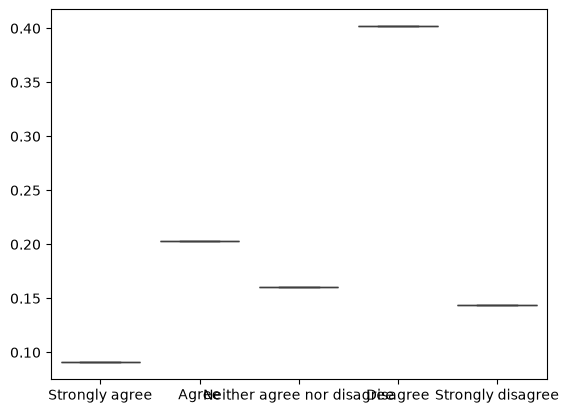

In [24]:
sample = male_dataset[0]
print(sample['question'])
sample['human_dist']
sns.boxplot(x = sample['option_texts'], y = sample['human_dist'])
(sample['human_dist'])
sample

In [101]:
m_rec

{'qid': '2022:v45',
 'year': '2022',
 'v': 'v45',
 'type': 'score',
 'question': 'Which of the following best applies to the sharing of household work between you and your spouse/partner?',
 'option_texts': ['I do much more than my fair share',
  'I do a bit more than my fair share',
  'I do roughly my fair share',
  'I do a bit less than my fair share',
  'I do much less than my fair share'],
 'country': 'United States',
 'personas': {'SEX': 'Male'},
 'attribute': 'SEX',
 'persona': 'Sex=Male',
 'n': 274,
 'human_dist': array([0.05474453, 0.09854015, 0.49270073, 0.22627737, 0.12773723])}

In [102]:
sex_by_qid = {}
for s in male_dataset:
    sex_by_qid.setdefault(s["qid"], {})[s["personas"]["SEX"]] = s

min_n = 50
mixed_rows = []
for qid, grp in sex_by_qid.items():
    if set(grp.keys()) != {"Male", "Female"}:
        raise ValueError(f"{qid}: expected Male and Female, got {set(grp.keys())}")
    m_rec, f_rec = grp["Male"], grp["Female"]
    if m_rec["type"] != "score" or len(m_rec['option_texts'])!=5 or min(m_rec["n"], f_rec["n"]) < min_n:
        continue
    m_dist, f_dist = m_rec["human_dist"], f_rec["human_dist"]
    scale_points = np.arange(1, len(m_dist) + 1, dtype=float)
    m_mean = float(np.dot(scale_points, m_dist))
    f_mean = float(np.dot(scale_points, f_dist))
    m_cns, f_cns = consensus(m_dist), consensus(f_dist)
    m_ent = float(-np.sum(m_dist * np.log2(m_dist + 1e-12)) / np.log2(len(m_dist)))
    f_ent = float(-np.sum(f_dist * np.log2(f_dist + 1e-12)) / np.log2(len(f_dist)))
    mixed_rows.append({
        "qid": qid,
        "question": m_rec["question"],
        "options": m_rec["option_texts"],
        "n_male": m_rec["n"],
        "n_female": f_rec["n"],
        "cns_male": round(m_cns, 3),
        "cns_female": round(f_cns, 3),
        "cns_diff": round(m_cns - f_cns, 3),
        "mean_male": round(m_mean, 3),
        "mean_female": round(f_mean, 3),
        "mean_diff": round(abs(m_mean - f_mean), 3),
        "male_dist": np.round(m_dist, 3),
        "female_dist": np.round(f_dist, 3),
    })

mixed_df = pd.DataFrame(mixed_rows).sort_values("mean_diff", ascending=False).reset_index(drop=True)
display(mixed_df[["qid", "n_male", "n_female", "mean_male", "mean_female", "mean_diff", "cns_male", "cns_female", "question"]].head(12))


,qid,n_male,n_female,mean_male,mean_female,mean_diff,cns_male,cns_female,question
0,2022:v45,274,236,3.274,2.275,0.998,0.659,0.652,Which of the following best applies to the sha...
1,2018:v27,476,677,2.437,1.976,0.461,0.436,0.559,Do you agree or disagree with the following st...
2,2021:v38,504,630,2.474,2.902,0.427,0.595,0.588,"During the past 12 months, how often did you v..."
3,2022:v15,539,568,2.596,2.176,0.419,0.510,0.654,Children grow up in different kinds of familie...
4,2021:v24,487,604,2.150,2.563,0.413,0.556,0.502,"During the past 12 months, how often, if at al..."
5,2022:v16,538,568,2.664,2.287,0.377,0.501,0.631,Children grow up in different kinds of familie...
6,2015:v72,131,178,2.985,3.360,0.375,0.560,0.536,To what extent do you agree or disagree with t...
7,2018:v29,476,681,3.061,2.690,0.371,0.451,0.453,Do you agree or disagree with the following st...
8,2022:v2,535,562,3.495,3.859,0.364,0.545,0.613,"To begin, we have some questions about women. ..."
9,2019:v31,780,983,3.418,3.779,0.361,0.488,0.531,Is it just or unjust – right or wrong – that p...


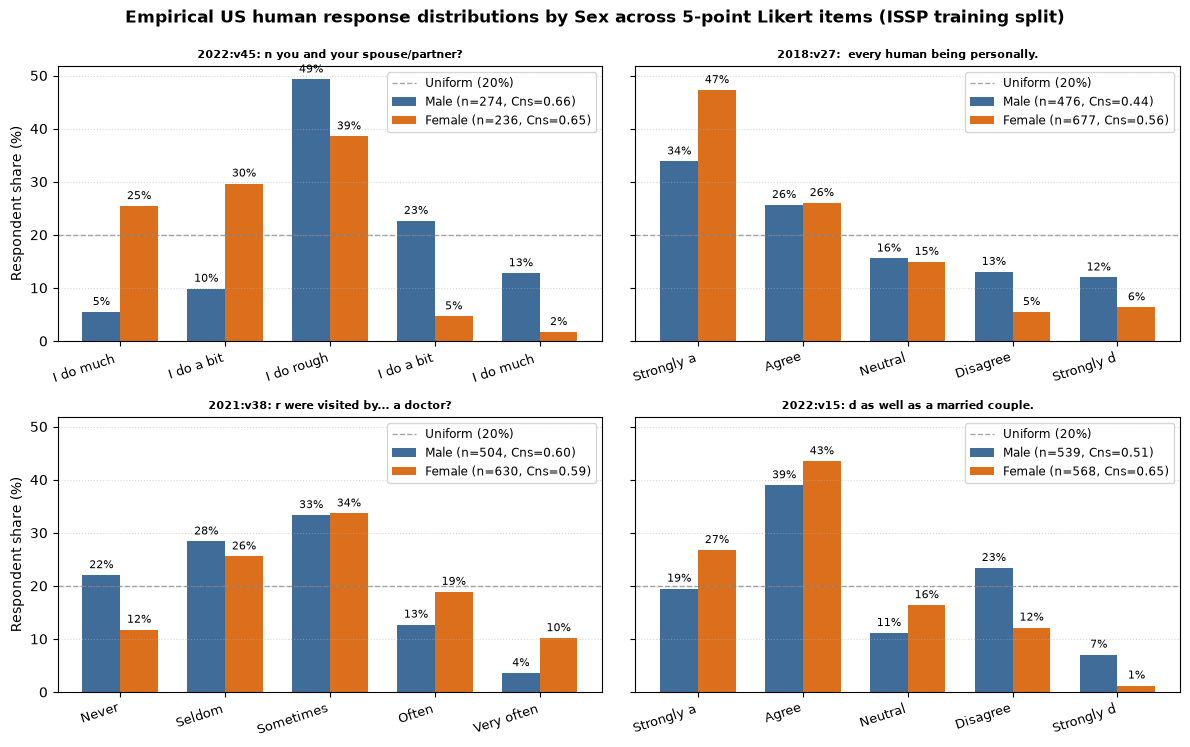

In [103]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7.5), sharey=True)
bar_width = 0.36

for ax, (_, row) in zip(axes.flat, mixed_df[['qid', 'question']].iterrows()):
    m_rec = sex_by_qid[row['qid']]["Male"]
    f_rec = sex_by_qid[row['qid']]["Female"]
    opts = m_rec["option_texts"]
    x = np.arange(len(opts))
    m_vals = m_rec["human_dist"] * 100.0
    f_vals = f_rec["human_dist"] * 100.0
    m_cns = consensus(m_rec["human_dist"])
    f_cns = consensus(f_rec["human_dist"])

    bars_m = ax.bar(x - bar_width / 2, m_vals, width=bar_width, label=f"Male (n={m_rec['n']}, Cns={m_cns:.2f})", color="#1B365D", alpha=0.9)
    bars_f = ax.bar(x + bar_width / 2, f_vals, width=bar_width, label=f"Female (n={f_rec['n']}, Cns={f_cns:.2f})", color="#9E2A2B", alpha=0.9)
    ax.axhline(20.0, color="#6E6A64", linestyle="--", linewidth=1.0, alpha=0.7, label="Uniform (20%)")

    for bar in list(bars_m) + list(bars_f):
        h = bar.get_height()
        ax.text(bar.get_x() + bar.get_width() / 2, h + 0.8, f"{h:.0f}%", ha="center", va="bottom", fontsize=8)

    short_opts = [o.replace("Neither agree nor disagree", "Neutral").replace("Neither willing nor unwilling", "Neutral") for o in opts]
    short_opts = [o[:10] for o in short_opts]
    ax.set_xticks(x)
    ax.set_xticklabels(short_opts, rotation=18, ha="right", fontsize=9)
    ax.set_title(f"{row['qid']}: {row['question'][-30:]}", fontsize=8, fontweight="bold")
    # ax.set_ylim(0, 42)
    ax.grid(axis="y", linestyle=":", alpha=0.5)
    ax.legend(frameon=True, fontsize=8.5, loc="upper right")

axes[0, 0].set_ylabel("Respondent share (%)")
axes[1, 0].set_ylabel("Respondent share (%)")
fig.suptitle("Empirical US human response distributions by Sex across 5-point Likert items (ISSP training split)", fontsize=12, fontweight="bold", y=0.99)
fig.tight_layout()

fig_dir = Path("../manuscript/figures")
fig_dir.mkdir(parents=True, exist_ok=True)
fig.savefig(fig_dir / "gender_mixed_distributions.pdf", bbox_inches="tight")
fig.savefig(fig_dir / "gender_mixed_distributions.png", dpi=300, bbox_inches="tight")
plt.show()

## Functions

In [104]:
import traceback


def free_gpu():
    if hasattr(sys, "last_traceback") and sys.last_traceback is not None:
        traceback.clear_frames(sys.last_traceback)
        sys.last_traceback = None
    if hasattr(sys, "last_value"):
        sys.last_value = None
    if hasattr(sys, "last_type"):
        sys.last_type = None
    if hasattr(sys, "last_exc"):
        sys.last_exc = None
    gc.collect()
    torch.cuda.empty_cache()


@torch.no_grad()
def predict_probs(model, records, batch_size=64, show_progress=True, autocast_bf16=False):
    was_training = model.training
    model.eval()
    preds = []
    iterator = range(0, len(records), batch_size)
    if show_progress:
        iterator = tqdm(iterator, desc="predict", unit="batch", leave=False)
    for start in iterator:
        batch = records[start:start + batch_size]
        prepared = [model.prepare(make_view(r)) for r in batch]
        if autocast_bf16:
            with torch.autocast("cuda", dtype=torch.bfloat16):
                logits_batch = model.forward([enc for enc, _ in prepared])
        else:
            logits_batch = model.forward([enc for enc, _ in prepared])
        for question_logits in logits_batch:
            if len(question_logits) != 1:
                raise ValueError(f"Expected 1 question per record, got {len(question_logits)}")
            preds.append(torch.softmax(question_logits[0].float(), dim=-1).cpu().numpy())
    if was_training:
        model.train()
    return preds


In [105]:
top4_qids = list(mixed_df["qid"].head(4))
eval_records = []
for qid in top4_qids:
    eval_records.append(sex_by_qid[qid]["Male"])
    eval_records.append(sex_by_qid[qid]["Female"])

## kev-0.8b - default

In [106]:
device = "cuda"
if "model" in globals():
    del model
free_gpu()
torch.backends.cuda.matmul.allow_tf32 = False
torch.backends.cudnn.allow_tf32 = False
torch.backends.cuda.enable_flash_sdp(False)
torch.backends.cuda.enable_mem_efficient_sdp(False)
model = KevPointerModel.load("jaredpalmer/kev-0.8b", device)
model.net.head.temperature = model.meta.temperature  # default Kev shipped temperature (2.35)
print(model.describe())
model.net.head.temperature

kev_preds = predict_probs(model, eval_records, show_progress=True)
kev_by_qid = {}
for i, qid in enumerate(top4_qids):
    kev_by_qid[qid] = {"Male": kev_preds[2 * i], "Female": kev_preds[2 * i + 1]}


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 9 files:   0%|          | 0/9 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/320 [00:00<?, ?it/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 9 files:   0%|          | 0/9 [00:00<?, ?it/s]

{'kind': 'kev', 'base': 'Qwen/Qwen3.5-0.8B-Base', 'mode': 'loaded', 'trainable_params': 524800}


predict:   0%|          | 0/1 [00:00<?, ?batch/s]

## Kev 0.8 - Fine-tuned

In [107]:
device = "cuda"
if "model" in globals():
    del model
free_gpu()

ft_ckpt = "runs/kev-0.8b-stage4-mix/best"
model = KevPointerModel.load(ft_ckpt, device)
model.net.head.temperature = 1.0
print(model.describe())
print("temperature:", model.net.head.temperature)

ft_preds = predict_probs(model, eval_records, show_progress=True)
ft_by_qid = {}
for i, qid in enumerate(top4_qids):
    ft_by_qid[qid] = {"Male": ft_preds[2 * i], "Female": ft_preds[2 * i + 1]}


Loading weights:   0%|          | 0/320 [00:00<?, ?it/s]

{'kind': 'kev', 'base': 'Qwen/Qwen3.5-0.8B-Base', 'mode': 'loaded', 'trainable_params': 524800}
temperature: 1.0


predict:   0%|          | 0/1 [00:00<?, ?batch/s]

# Plots

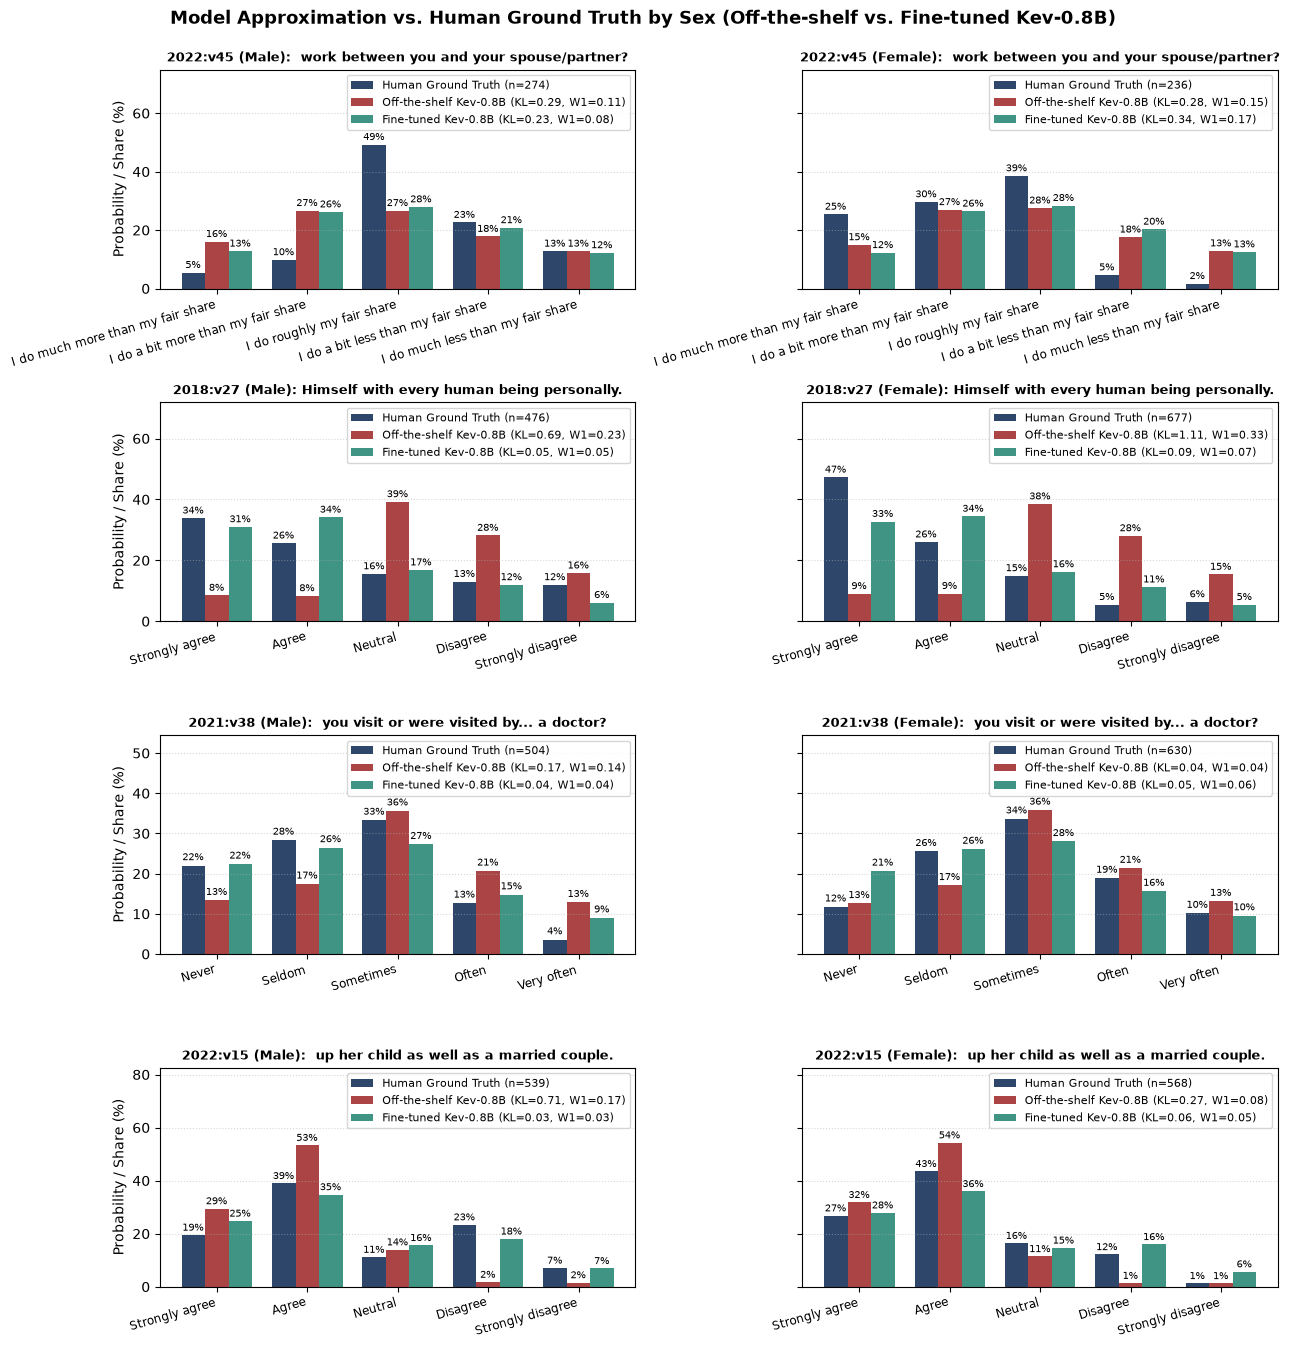

In [115]:
def dist_kl_w1(human_dist, model_dist):
    clipped = np.clip(model_dist, 1e-12, 1.0)
    mask = human_dist > 0
    kl = float(np.sum(human_dist[mask] * np.log2(human_dist[mask] / clipped[mask])))
    w1 = float(np.abs(np.cumsum(human_dist)[:-1] - np.cumsum(model_dist)[:-1]).sum() / (len(human_dist) - 1))
    return kl, w1

fig, axes = plt.subplots(4, 2, figsize=(13, 13.5), sharey="row")
bar_w = 0.26

for row_idx, (_, row) in enumerate(mixed_df[["qid", "question"]].head(4).iterrows()):
    qid = row["qid"]
    opts = sex_by_qid[qid]["Male"]["option_texts"]
    short_opts = [o.replace("Neither agree nor disagree", "Neutral").replace("Neither willing nor unwilling", "Neutral") for o in opts]
    x = np.arange(len(opts))

    for col_idx, sex in enumerate(["Male", "Female"]):
        ax = axes[row_idx, col_idx]
        rec = sex_by_qid[qid][sex]
        h_dist = rec["human_dist"]
        k_dist = kev_by_qid[qid][sex]
        f_dist = ft_by_qid[qid][sex]

        k_kl, k_w1 = dist_kl_w1(h_dist, k_dist)
        f_kl, f_w1 = dist_kl_w1(h_dist, f_dist)

        b_h = ax.bar(x - bar_w, h_dist * 100.0, width=bar_w, color="#1B365D", alpha=0.92,
                     label=f"Human Ground Truth (n={rec['n']})")
        b_k = ax.bar(x, k_dist * 100.0, width=bar_w, color="#9E2A2B", alpha=0.88,
                     label=f"Off-the-shelf Kev-0.8B (KL={k_kl:.2f}, W1={k_w1:.2f})")
        b_f = ax.bar(x + bar_w, f_dist * 100.0, width=bar_w, color="#2E8B78", alpha=0.92,
                     label=f"Fine-tuned Kev-0.8B (KL={f_kl:.2f}, W1={f_w1:.2f})")

        for bar in list(b_h) + list(b_k) + list(b_f):
            h = bar.get_height()
            ax.text(bar.get_x() + bar.get_width() / 2, h + 0.7, f"{h:.0f}%", ha="center", va="bottom", fontsize=7.5)

        top_y = max(h_dist.max(), k_dist.max(), f_dist.max()) * 100.0
        ax.set_ylim(0, max(ax.get_ylim()[1], top_y * 1.52))
        ax.set_xticks(x)
        ax.set_xticklabels(short_opts, rotation=16, ha="right", fontsize=8.5)
        ax.set_title(f"{qid} ({sex}): {row['question'][-42:]}", fontsize=9.5, fontweight="bold")
        ax.grid(axis="y", linestyle=":", alpha=0.5)
        ax.legend(frameon=True, fontsize=8, loc="upper right")
        if col_idx == 0:
            ax.set_ylabel("Probability / Share (%)")

fig.suptitle("Model Approximation vs. Human Ground Truth by Sex (Off-the-shelf vs. Fine-tuned Kev-0.8B)", fontsize=13, fontweight="bold", y=0.995)
fig.tight_layout()

fig_dir = Path("../manuscript/figures")
fig_dir.mkdir(parents=True, exist_ok=True)
fig.savefig(fig_dir / "gender_mixed_model_vs_human.pdf", bbox_inches="tight")
fig.savefig(fig_dir / "gender_mixed_model_vs_human.png", dpi=300, bbox_inches="tight")
plt.show()

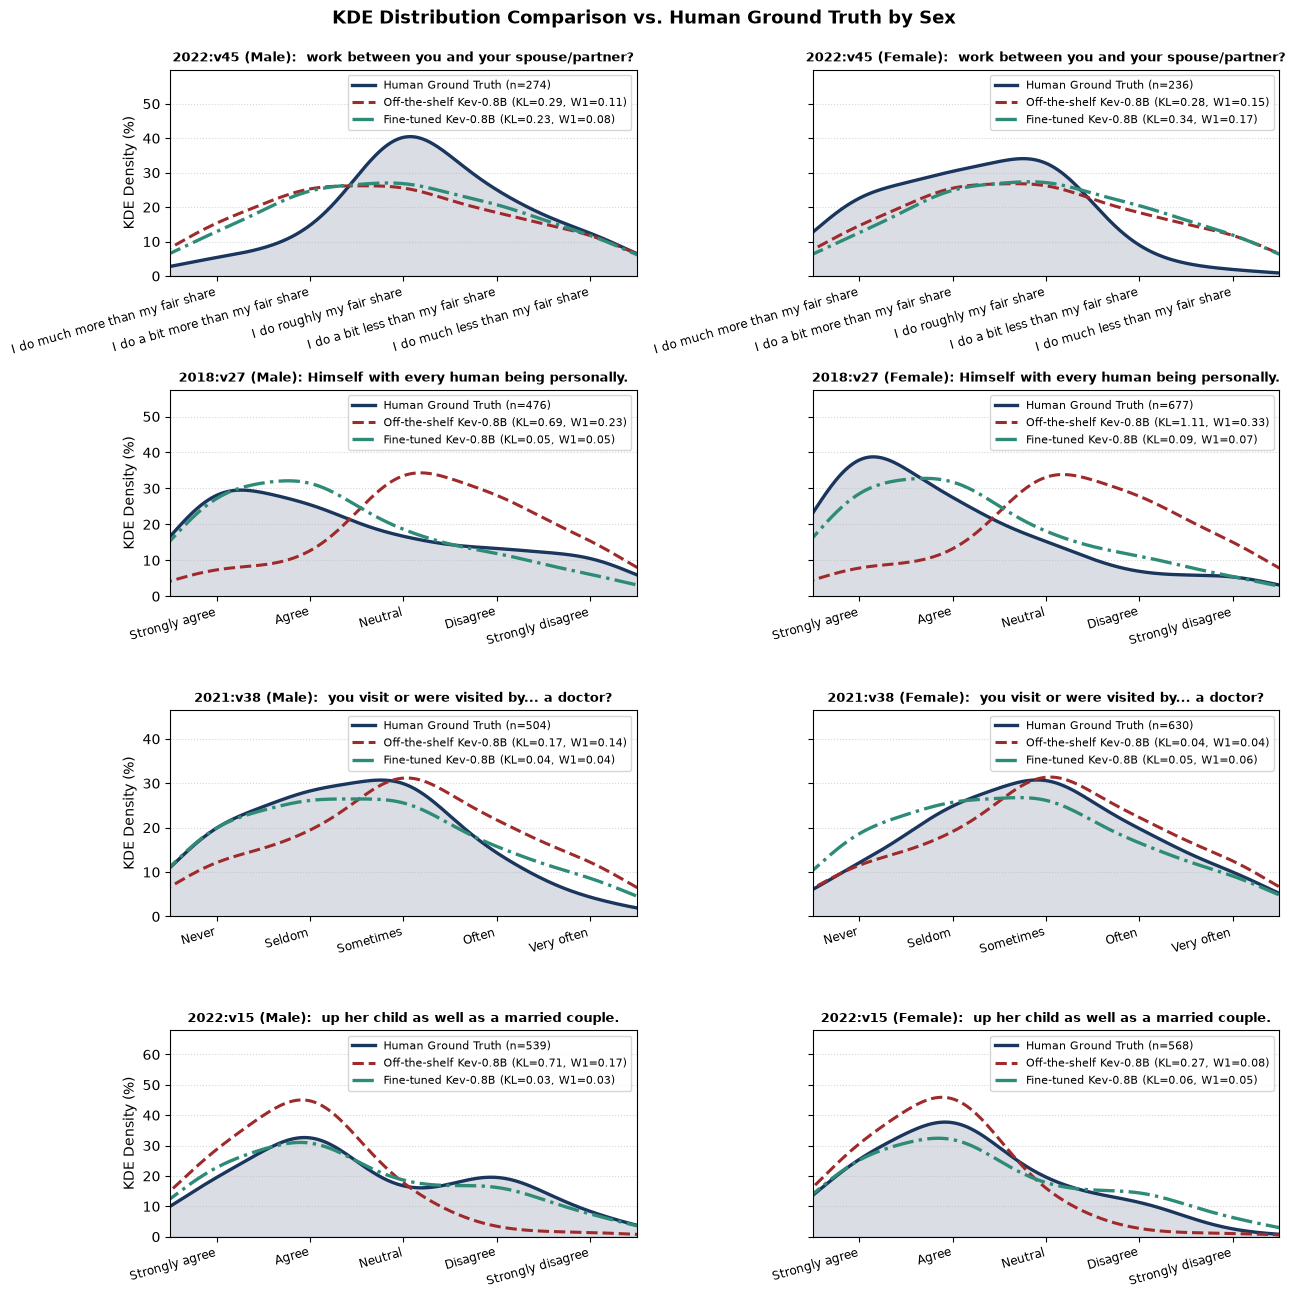

In [116]:
def discrete_kde_curve(probs, x_grid, bw=0.55):
    centers = np.arange(len(probs), dtype=float)
    kernels = np.exp(-0.5 * ((x_grid[:, None] - centers[None, :]) / bw) ** 2) / (bw * np.sqrt(2.0 * np.pi))
    return (kernels @ probs) * 100.0

fig, axes = plt.subplots(4, 2, figsize=(13, 13.0), sharey="row")

for row_idx, (_, row) in enumerate(mixed_df[["qid", "question"]].head(4).iterrows()):
    qid = row["qid"]
    opts = sex_by_qid[qid]["Male"]["option_texts"]
    short_opts = [o.replace("Neither agree nor disagree", "Neutral").replace("Neither willing nor unwilling", "Neutral") for o in opts]
    x = np.arange(len(opts), dtype=float)
    x_grid = np.linspace(-0.6, len(opts) - 0.4, 300)

    for col_idx, sex in enumerate(["Male", "Female"]):
        ax = axes[row_idx, col_idx]
        rec = sex_by_qid[qid][sex]
        h_dist = rec["human_dist"]
        k_dist = kev_by_qid[qid][sex]
        f_dist = ft_by_qid[qid][sex]

        k_kl, k_w1 = dist_kl_w1(h_dist, k_dist)
        f_kl, f_w1 = dist_kl_w1(h_dist, f_dist)

        h_kde = discrete_kde_curve(h_dist, x_grid)
        k_kde = discrete_kde_curve(k_dist, x_grid)
        f_kde = discrete_kde_curve(f_dist, x_grid)

        ax.fill_between(x_grid, h_kde, color="#1B365D", alpha=0.16)
        ax.plot(x_grid, h_kde, color="#1B365D", linewidth=2.4, label=f"Human Ground Truth (n={rec['n']})")
        ax.plot(x_grid, k_kde, color="#9E2A2B", linewidth=2.2, linestyle="--", label=f"Off-the-shelf Kev-0.8B (KL={k_kl:.2f}, W1={k_w1:.2f})")
        ax.plot(x_grid, f_kde, color="#2E8B78", linewidth=2.4, linestyle="-.", label=f"Fine-tuned Kev-0.8B (KL={f_kl:.2f}, W1={f_w1:.2f})")

        top_y = max(h_kde.max(), k_kde.max(), f_kde.max())
        ax.set_ylim(0, max(ax.get_ylim()[1], top_y * 1.48))
        ax.set_xlim(-0.5, len(opts) - 0.5)
        ax.set_xticks(x)
        ax.set_xticklabels(short_opts, rotation=16, ha="right", fontsize=8.5)
        ax.set_title(f"{qid} ({sex}): {row['question'][-42:]}", fontsize=9.5, fontweight="bold")
        ax.grid(axis="y", linestyle=":", alpha=0.5)
        ax.legend(frameon=True, fontsize=8, loc="upper right")
        if col_idx == 0:
            ax.set_ylabel("KDE Density (%)")

fig.suptitle("KDE Distribution Comparison vs. Human Ground Truth by Sex", fontsize=13, fontweight="bold", y=0.995)
fig.tight_layout()

fig_dir = Path("../manuscript/figures")
fig.savefig(fig_dir / "gender_mixed_kde_vs_human.pdf", bbox_inches="tight")
fig.savefig(fig_dir / "gender_mixed_kde_vs_human.png", dpi=300, bbox_inches="tight")
plt.show()

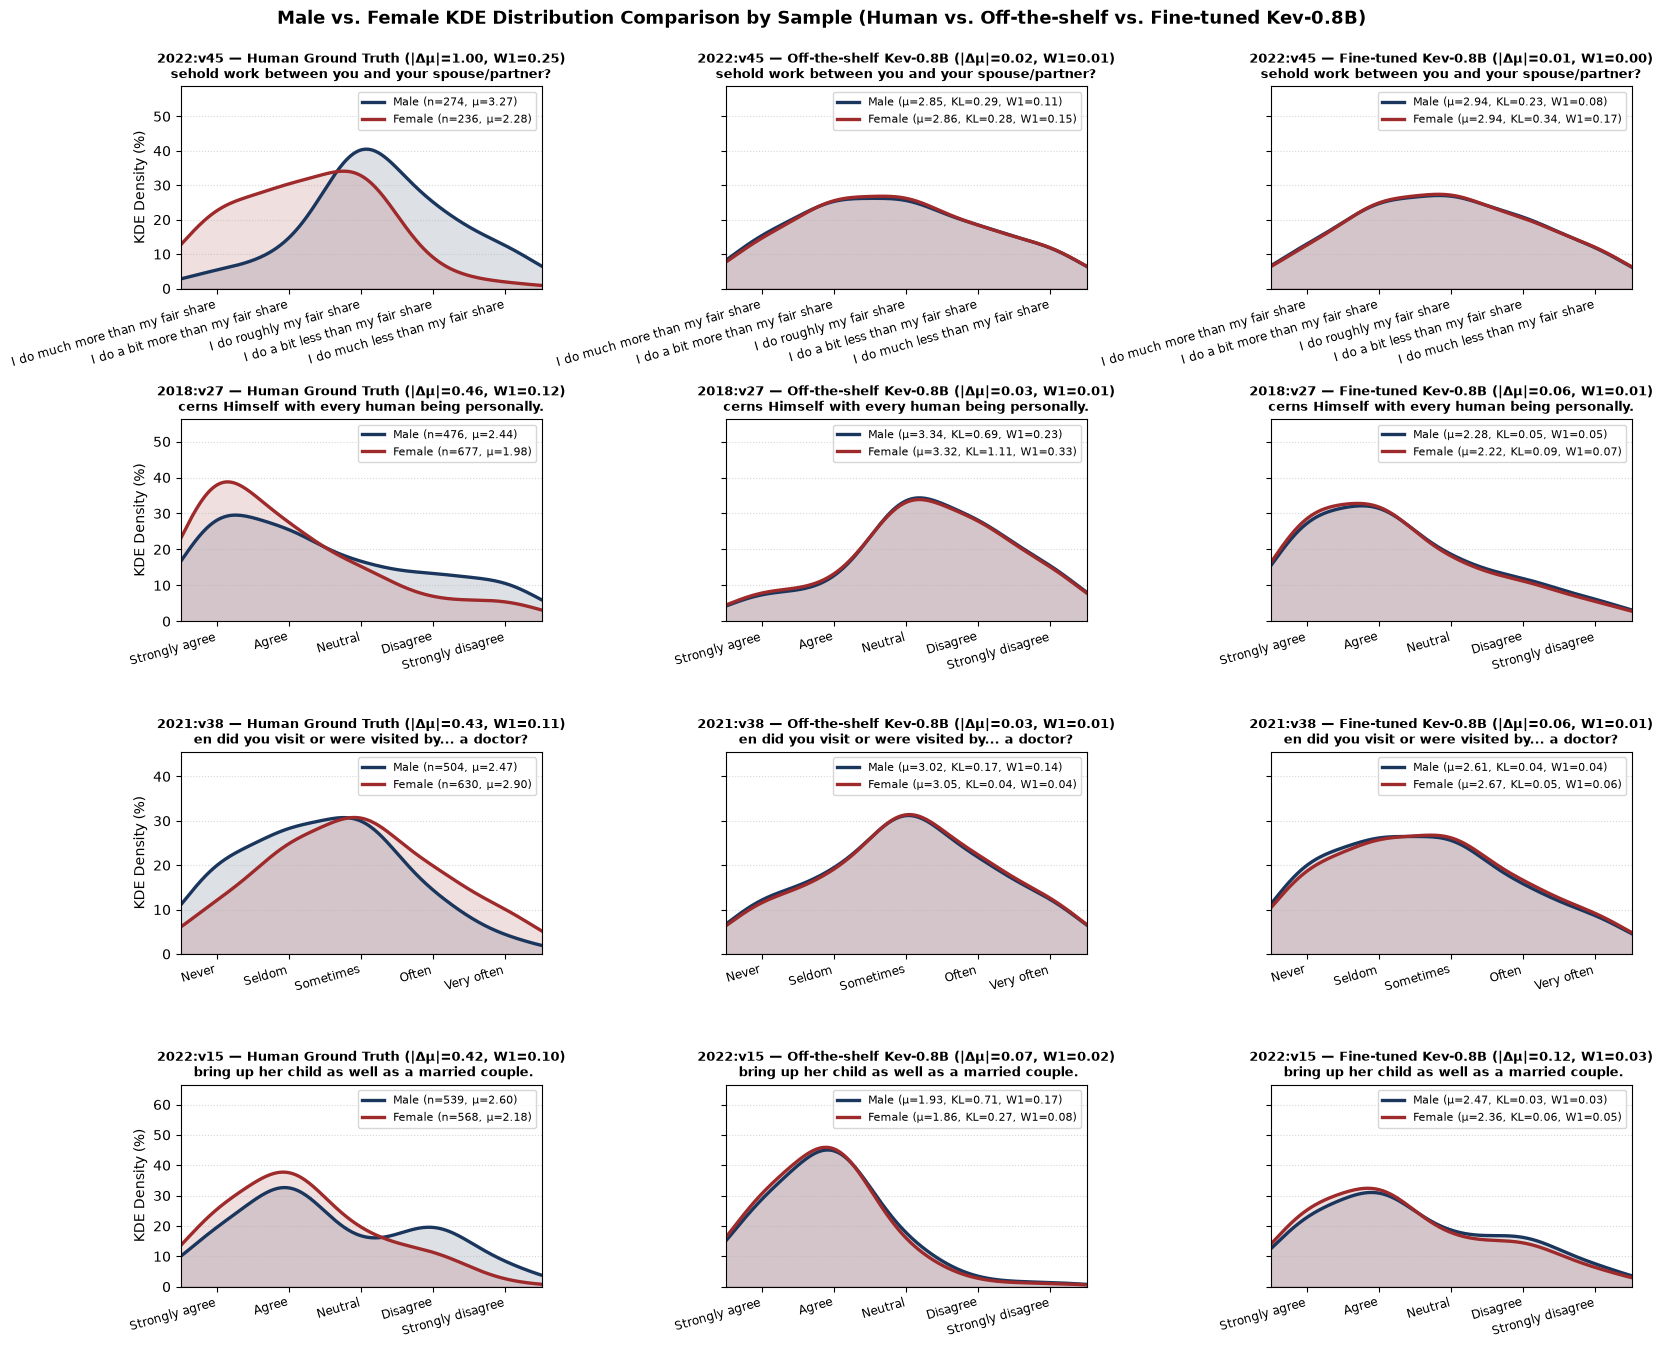

In [117]:
fig, axes = plt.subplots(4, 3, figsize=(16.5, 13.5), sharey="row")

sample_sources = [
    ("Human Ground Truth", lambda qid, sex: sex_by_qid[qid][sex]["human_dist"]),
    ("Off-the-shelf Kev-0.8B", lambda qid, sex: kev_by_qid[qid][sex]),
    ("Fine-tuned Kev-0.8B", lambda qid, sex: ft_by_qid[qid][sex]),
]

for row_idx, (_, row) in enumerate(mixed_df[["qid", "question"]].head(4).iterrows()):
    qid = row["qid"]
    m_rec = sex_by_qid[qid]["Male"]
    f_rec = sex_by_qid[qid]["Female"]
    opts = m_rec["option_texts"]
    short_opts = [o.replace("Neither agree nor disagree", "Neutral").replace("Neither willing nor unwilling", "Neutral") for o in opts]
    x = np.arange(len(opts), dtype=float)
    x_grid = np.linspace(-0.6, len(opts) - 0.4, 300)
    scale_pts = np.arange(1, len(opts) + 1, dtype=float)

    for col_idx, (sample_name, get_dist) in enumerate(sample_sources):
        ax = axes[row_idx, col_idx]
        m_dist = get_dist(qid, "Male")
        f_dist = get_dist(qid, "Female")

        m_kde = discrete_kde_curve(m_dist, x_grid)
        f_kde = discrete_kde_curve(f_dist, x_grid)

        m_mean = float(np.dot(scale_pts, m_dist))
        f_mean = float(np.dot(scale_pts, f_dist))
        sex_kl, sex_w1 = dist_kl_w1(m_dist, f_dist)

        if sample_name == "Human Ground Truth":
            m_label = f"Male (n={m_rec['n']}, μ={m_mean:.2f})"
            f_label = f"Female (n={f_rec['n']}, μ={f_mean:.2f})"
        else:
            m_kl, m_w1 = dist_kl_w1(m_rec["human_dist"], m_dist)
            f_kl, f_w1 = dist_kl_w1(f_rec["human_dist"], f_dist)
            m_label = f"Male (μ={m_mean:.2f}, KL={m_kl:.2f}, W1={m_w1:.2f})"
            f_label = f"Female (μ={f_mean:.2f}, KL={f_kl:.2f}, W1={f_w1:.2f})"

        ax.fill_between(x_grid, m_kde, color="#1B365D", alpha=0.15)
        ax.plot(x_grid, m_kde, color="#1B365D", linewidth=2.4, linestyle="-", label=m_label)
        ax.fill_between(x_grid, f_kde, color="#9E2A2B", alpha=0.15)
        ax.plot(x_grid, f_kde, color="#9E2A2B", linewidth=2.4, linestyle="-", label=f_label)

        top_y = max(m_kde.max(), f_kde.max())
        ax.set_ylim(0, max(ax.get_ylim()[1], top_y * 1.45))
        ax.set_xlim(-0.5, len(opts) - 0.5)
        ax.set_xticks(x)
        ax.set_xticklabels(short_opts, rotation=16, ha="right", fontsize=8.5)
        ax.set_title(
            f"{qid} — {sample_name} (|Δμ|={abs(m_mean - f_mean):.2f}, W1={sex_w1:.2f})\n{row['question'][-48:]}",
            fontsize=9.0,
            fontweight="bold",
        )
        ax.grid(axis="y", linestyle=":", alpha=0.5)
        ax.legend(frameon=True, fontsize=8, loc="upper right")
        if col_idx == 0:
            ax.set_ylabel("KDE Density (%)")

fig.suptitle("Male vs. Female KDE Distribution Comparison by Sample (Human vs. Off-the-shelf vs. Fine-tuned Kev-0.8B)", fontsize=13, fontweight="bold", y=0.995)
fig.tight_layout()

fig_dir = Path("../manuscript/figures")
fig.savefig(fig_dir / "gender_mixed_kde_by_sample.pdf", bbox_inches="tight")
fig.savefig(fig_dir / "gender_mixed_kde_by_sample.png", dpi=300, bbox_inches="tight")
plt.show()

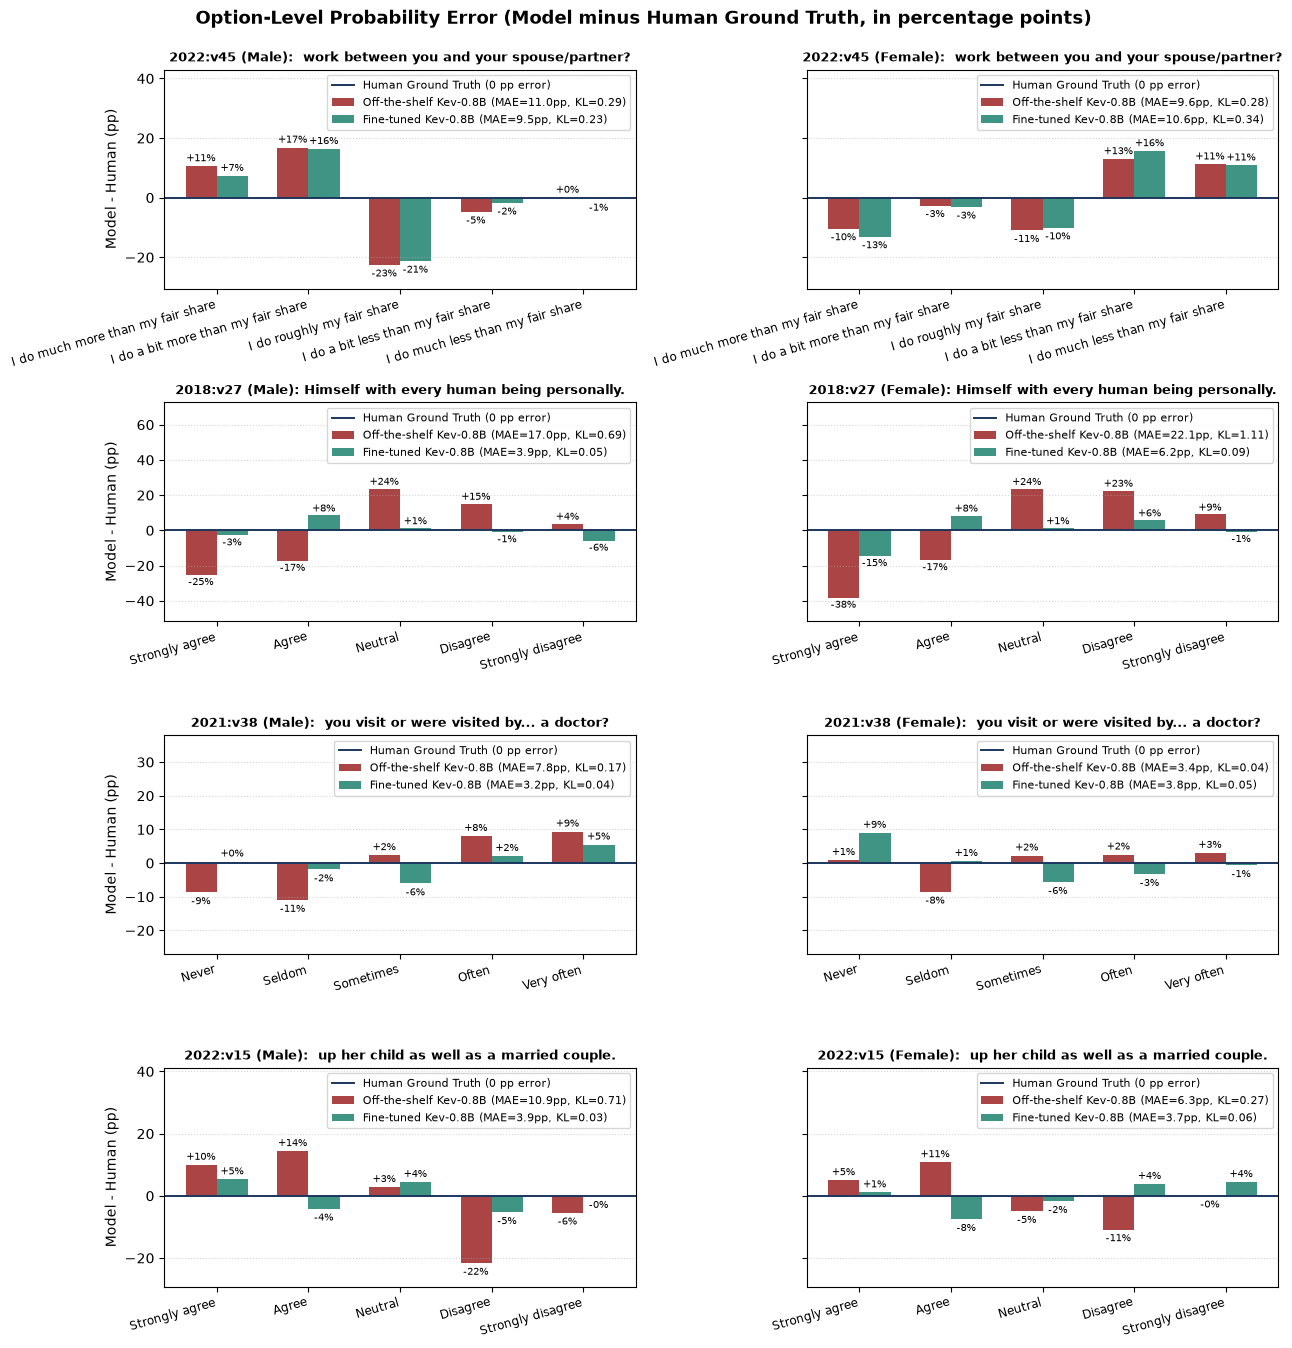

In [118]:
fig, axes = plt.subplots(4, 2, figsize=(13, 13.5), sharey="row")
bar_w = 0.34

for row_idx, (_, row) in enumerate(mixed_df[["qid", "question"]].head(4).iterrows()):
    qid = row["qid"]
    opts = sex_by_qid[qid]["Male"]["option_texts"]
    short_opts = [o.replace("Neither agree nor disagree", "Neutral").replace("Neither willing nor unwilling", "Neutral") for o in opts]
    x = np.arange(len(opts))

    for col_idx, sex in enumerate(["Male", "Female"]):
        ax = axes[row_idx, col_idx]
        rec = sex_by_qid[qid][sex]
        h_dist = rec["human_dist"]
        k_dist = kev_by_qid[qid][sex]
        f_dist = ft_by_qid[qid][sex]

        k_diff = (k_dist - h_dist) * 100.0
        f_diff = (f_dist - h_dist) * 100.0
        k_mae = float(np.abs(k_diff).mean())
        f_mae = float(np.abs(f_diff).mean())
        k_kl, k_w1 = dist_kl_w1(h_dist, k_dist)
        f_kl, f_w1 = dist_kl_w1(h_dist, f_dist)

        ax.axhline(0.0, color="#1B365D", linewidth=1.4, linestyle="-", label="Human Ground Truth (0 pp error)")
        b_k = ax.bar(x - bar_w / 2, k_diff, width=bar_w, color="#9E2A2B", alpha=0.88,
                     label=f"Off-the-shelf Kev-0.8B (MAE={k_mae:.1f}pp, KL={k_kl:.2f})")
        b_f = ax.bar(x + bar_w / 2, f_diff, width=bar_w, color="#2E8B78", alpha=0.92,
                     label=f"Fine-tuned Kev-0.8B (MAE={f_mae:.1f}pp, KL={f_kl:.2f})")

        for bar in list(b_k) + list(b_f):
            h = bar.get_height()
            va = "bottom" if h >= 0 else "top"
            offset = 0.8 if h >= 0 else -1.2
            ax.text(bar.get_x() + bar.get_width() / 2, h + offset, f"{h:+.0f}%", ha="center", va=va, fontsize=7.5)

        max_abs = max(np.abs(k_diff).max(), np.abs(f_diff).max(), 20.0)
        cur_low, cur_high = ax.get_ylim()
        ax.set_ylim(min(cur_low, -max_abs * 1.35), max(cur_high, max_abs * 1.90))
        ax.set_xticks(x)
        ax.set_xticklabels(short_opts, rotation=16, ha="right", fontsize=8.5)
        ax.set_title(f"{qid} ({sex}): {row['question'][-42:]}", fontsize=9.5, fontweight="bold")
        ax.grid(axis="y", linestyle=":", alpha=0.5)
        ax.legend(frameon=True, fontsize=8, loc="upper right")
        if col_idx == 0:
            ax.set_ylabel("Model - Human (pp)")

fig.suptitle("Option-Level Probability Error (Model minus Human Ground Truth, in percentage points)", fontsize=13, fontweight="bold", y=0.995)
fig.tight_layout()

fig_dir = Path("../manuscript/figures")
fig.savefig(fig_dir / "gender_mixed_diff_vs_human.pdf", bbox_inches="tight")
fig.savefig(fig_dir / "gender_mixed_diff_vs_human.png", dpi=300, bbox_inches="tight")
plt.show()